In [1]:
import pandas as pd
import numpy as np
from datetime import date
import matplotlib.pyplot as plt
from scipy.stats import boxcox
from scipy.special import inv_boxcox
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error

In [6]:
#Loading Dataset
data_df = pd.read_csv("Stock Trading of Nepal Infrastructure Bank Limited.csv")
data_df = data_df.drop(columns=["Symbol", "Open", "High", "Low", "Volume", "Turn Over", "Percent Change"])
data_df["Date"] = pd.to_datetime(data_df["Date"], dayfirst= True)
data_df = data_df.sort_values("Date").reset_index(drop=True)
data_df.head()

,Date,Close
0,2021-10-05,336.0
1,2021-10-06,344.0
2,2021-10-10,344.0
3,2021-10-11,361.5
4,2021-10-17,360.0


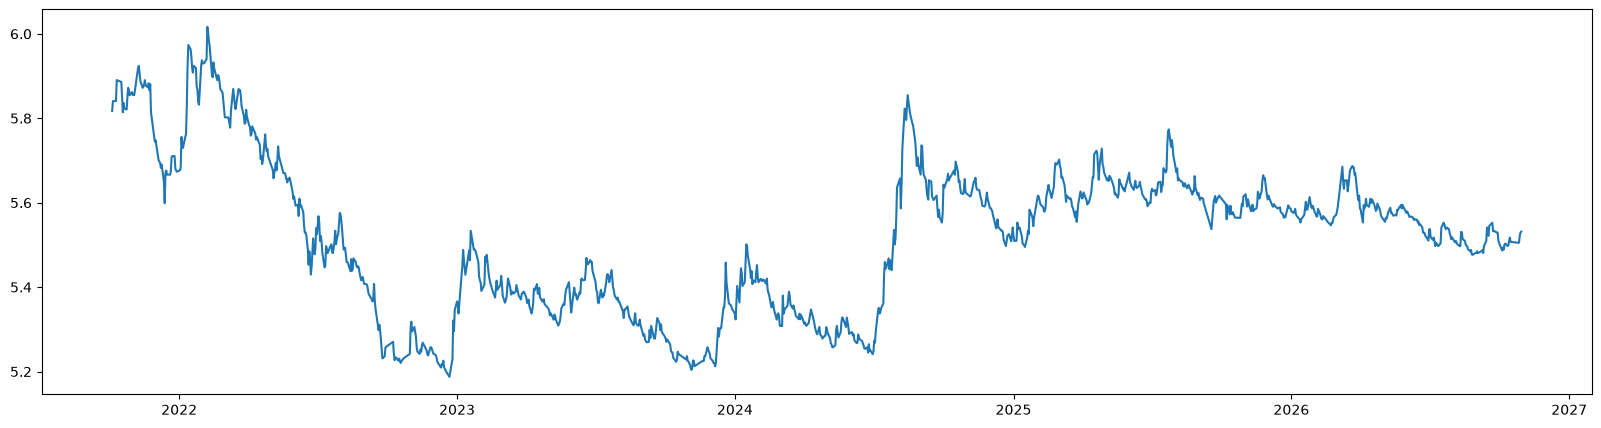

In [7]:
#Check for stationary
data_df["Close_log"] = np.log(data_df["Close"])

plt.figure(figsize=(20,5))
plt.plot(data_df["Date"], data_df["Close_log"])

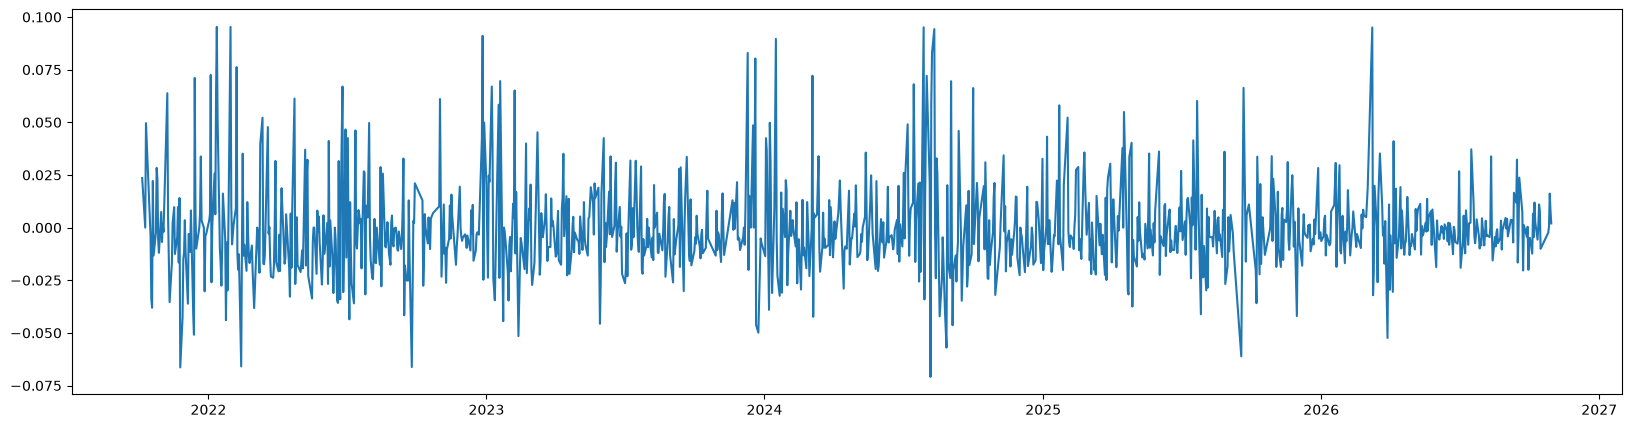

In [8]:
data_df["Close_log_diff"] = data_df["Close_log"].diff()
plt.figure(figsize=(20,5))
plt.plot(data_df["Date"], data_df["Close_log_diff"])

In [9]:
#ADF Test
def adf_test(series):
    """Using an ADF test to determne if a series is stationary"""
    test_results = adfuller(series)
    print("ADF Statistics = ", test_results[0])
    print("P-Value", test_results[1])
    print("Critical Values:")
    for thres, adf_stat in test_results[4].items():
        print("\t%s: %.2f" % (thres, adf_stat))

adf_test(data_df["Close_log_diff"][1:])

ADF Statistics =  -26.507659038233307
P-Value 0.0
Critical Values:
	1%: -3.44
	5%: -2.86
	10%: -2.57


C:\Users\User\AppData\Local\Temp\ipykernel_12600\301443237.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  test_results = adfuller(series)


* The data is stationary: The Augmented Dickey-Fuller (ADF) test confirms that data has a constant mean, variance, and autocorrelation structure over time. We do not need further differencing.
* Highly statistically significant: The P-value is exactly 0.0 (or infinitesimally close to it), well below the standard 0.05 threshold.
* Strong rejection of the null hypothesis: ADF statistic (-26.50) is far more negative than any of the critical values.


<function matplotlib.pyplot.show(close=None, block=None)>

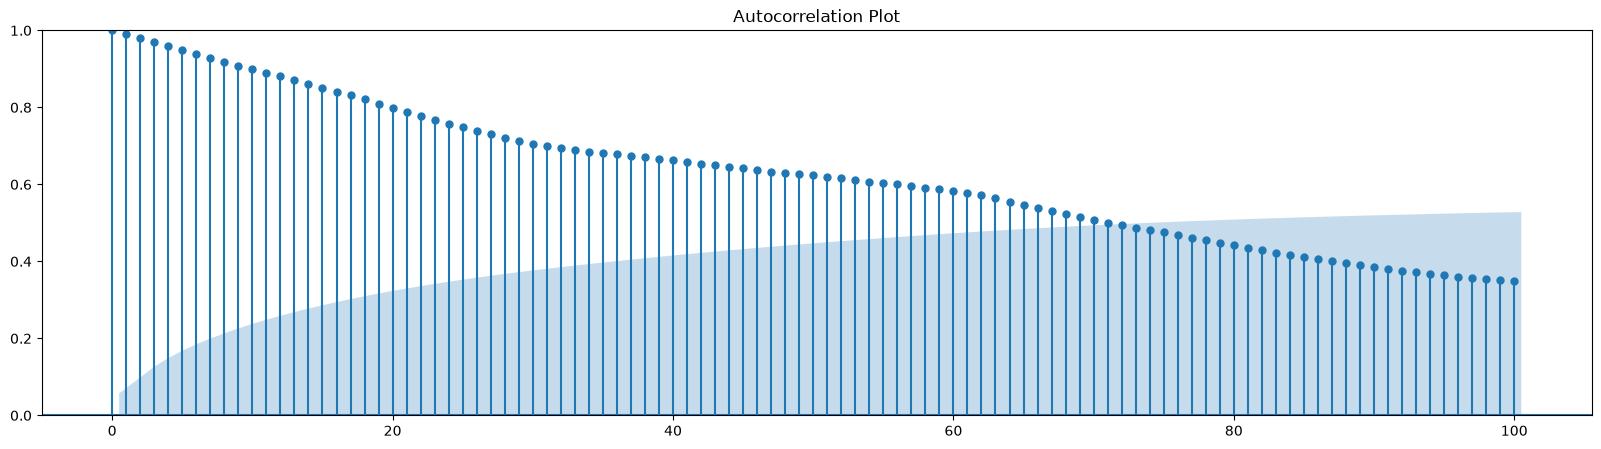

In [ ]:
#Auto Correlation
plt.rc("figure", figsize= (20,5))
plot_acf(data_df["Close"], lags= 100)
plt.title("Autocorrelation Plot")
plt.ylim(0,1)
plt.show

We can observe that there is a cascading downward pattern in lag. The strength of correlation is slowly decreasing as lags increases. 
Since the data is indexed by day to day date, the next day data forecast should only probably only consider ~ 75 of previous valuses due to their statistical significance.

The blue region shows that after approximate lag 70, the lags stop becoming statistically significant.

<function matplotlib.pyplot.show(close=None, block=None)>

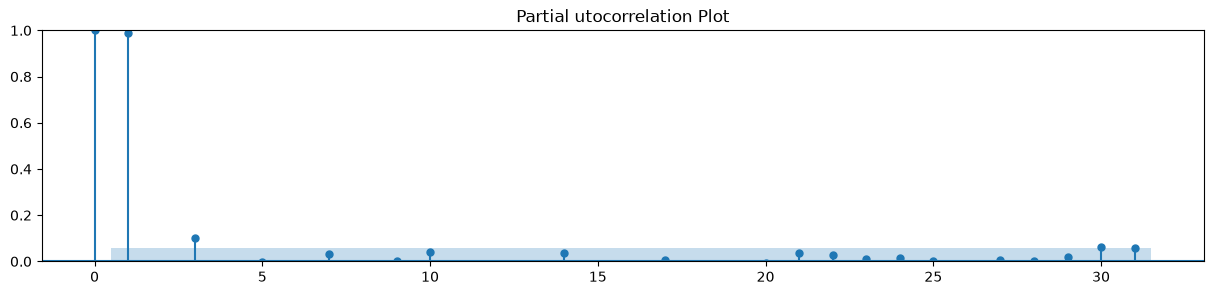

In [11]:
#Partial Auto Correlation
plt.rc("figure", figsize= (15,3))
plot_pacf(data_df["Close"], method= "ywm")
plt.title("Partial utocorrelation Plot")
plt.ylim(0,1)
plt.show

We see that lag 1 is highly correlated but other lags are not so higly correlated.

However, from this plot it is quite unclear how many autoregressors we would choose if we were to build a forecasting model. Therefore, it is often recommended to simply carry out a grid search over possible parameters using modelling packages such as auto arima.

##### ARIMA

### Core Requirements for ARIMA in Stock Data

1. Univariate Data: The model operates on a single continuous variable over time (such as closing stock prices or daily returns), rather than multiple interacting financial indicators simultaneously.
2. Stationarity: The statistical properties of the series—specifically its mean, variance, and autocorrelation—must remain constant over time. Raw stock prices are typically non-stationary (they exhibit upward/downward trends or random walks).
3. Differencing (d): To achieve stationarity, non-stationary stock data must undergo differencing (subtracting the previous observation from the current observation) one or more times, controlled by parameter d. Stationarity is typically verified using statistical tests like the Augmented Dickey-Fuller (ADF) test (p < 0.05).
4. Parameter Identification (p, d, q):
	* p (Autoregressive order): Determined by analyzing the Partial Autocorrelation Function (PACF) plot to see how past lag values influence the current price.
	* d (Integrated order): The number of differencing steps required to make the series stationary.
	* q (Moving Average order): Determined using the Autocorrelation Function (ACF) plot to evaluate past prediction errors (residuals).

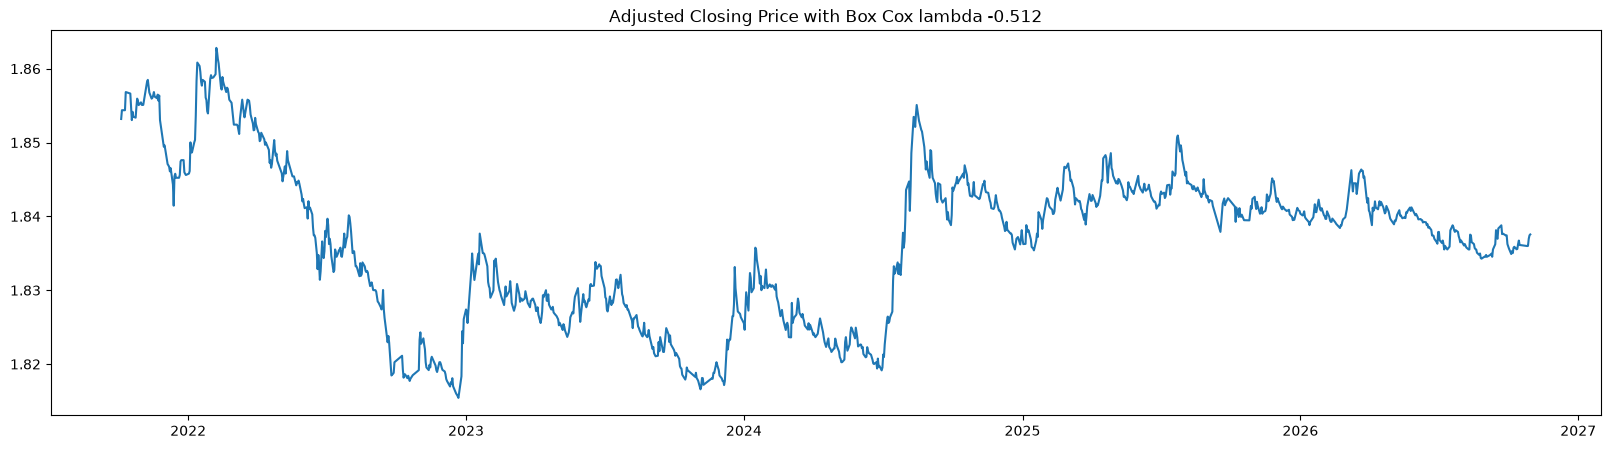

In [12]:
#Box Cox Transform - (Transforming non normal data to normal distribution)
data_df["Close_Boxcox"], lam = boxcox(data_df["Close"])
plt.figure(figsize=(20,5))
plt.title(f"Adjusted Closing Price with Box Cox lambda {lam.round(3)}")
plt.plot(data_df["Date"], data_df["Close_Boxcox"])

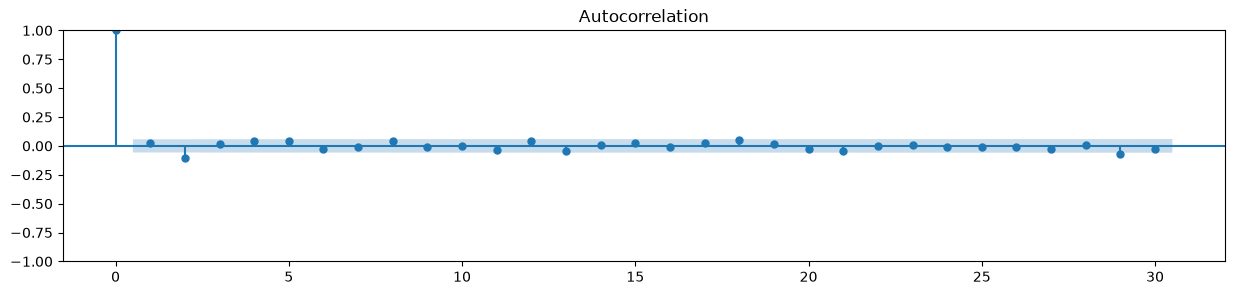

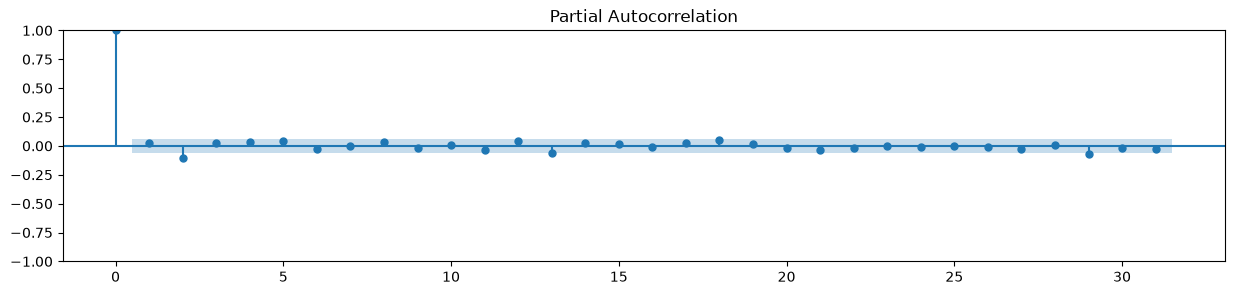

In [13]:
data_df["Close_diff"] = data_df["Close_Boxcox"].diff()
data_df.dropna(inplace=True)

plot_acf(data_df["Close_diff"], lags= 30)
plot_pacf(data_df["Close_diff"], method= "ywm")
plt.show()

THe blue region signifies were the points are no longer statistically significant and from the plot we see the last ag that is statistically significant for both plot is ~2nd. Therefore we would take order of p and q to be 2. 

In [14]:
adf_test(data_df["Close_diff"][1:])

ADF Statistics =  -26.620923420860827
P-Value 0.0
Critical Values:
	1%: -3.44
	5%: -2.86
	10%: -2.57


C:\Users\User\AppData\Local\Temp\ipykernel_12600\301443237.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  test_results = adfuller(series)


In [45]:
#Splitting train and test
X = data_df.iloc[:int(len(data_df)*.80)]
y = data_df.iloc[int(len(data_df)*.80):]

#Building a model
model = ARIMA(X["Close_log"].to_numpy(), order= (75, 1, 2)).fit()
multi_pred = np.exp(model.forecast(steps= len(y))).round(2)

c:\Users\User\Desktop\DSML\StockPredictor\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\User\Desktop\DSML\StockPredictor\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\User\Desktop\DSML\StockPredictor\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [49]:
multi_pred

array([270.16, 268.37, 270.85, 273.27, 269.39, 269.84, 270.22, 271.46,
       271.48, 270.74, 273.56, 273.92, 275.37, 274.18, 273.95, 273.98,
       272.94, 274.43, 273.27, 272.35, 270.19, 269.81, 270.57, 270.24,
       271.63, 271.44, 272.66, 273.06, 270.38, 272.05, 272.82, 273.12,
       271.75, 272.04, 271.93, 271.28, 272.27, 274.38, 274.54, 271.28,
       272.85, 273.26, 271.93, 273.13, 273.17, 272.43, 274.14, 272.4 ,
       273.78, 273.76, 274.23, 273.45, 276.03, 274.18, 274.34, 274.19,
       273.38, 273.27, 272.81, 273.11, 273.72, 274.36, 273.67, 274.64,
       274.14, 274.54, 274.21, 274.6 , 274.75, 274.92, 273.87, 274.28,
       273.6 , 273.52, 273.97, 273.97, 274.04, 273.68, 273.59, 273.7 ,
       273.45, 272.89, 273.17, 273.34, 272.87, 272.93, 273.12, 273.18,
       273.4 , 273.31, 273.65, 273.35, 273.02, 273.61, 273.33, 273.12,
       273.13, 273.12, 272.97, 273.59, 272.83, 273.23, 273.42, 273.21,
       273.47, 273.68, 273.16, 273.32, 273.21, 273.14, 273.46, 273.3 ,
      

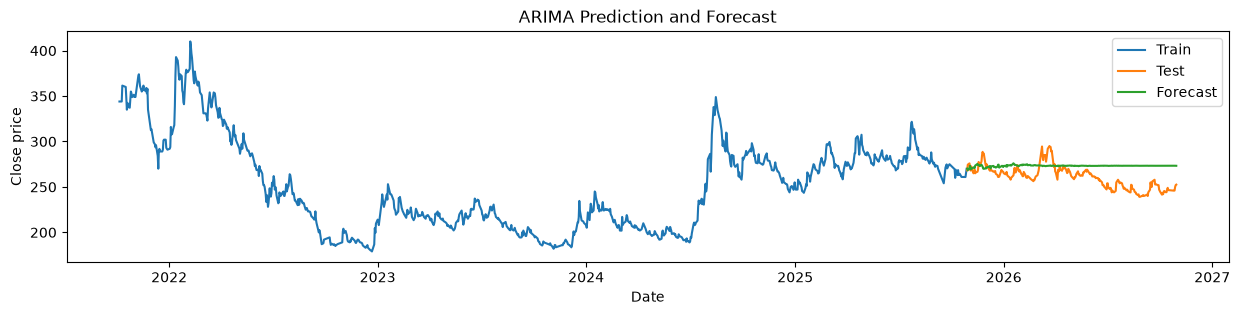

<function matplotlib.pyplot.show(close=None, block=None)>

In [47]:
plt.Figure(figsize=(20,5))
plt.title("ARIMA Prediction and Forecast")
plt.plot(X["Date"], X["Close"], label= "Train")
plt.plot(y["Date"], y["Close"], label= "Test")
plt.plot(y["Date"], multi_pred, label= "Forecast")
plt.xlabel("Date"); plt.ylabel("Close price")
plt.legend(); plt.show()
plt.show

In [ ]:
# Compare against a naive baseline 
naive = y["Close"].shift(1).iloc[1:]
print("MAE multi-step :", round(mean_absolute_error(y["Close"], multi_pred), 3))
print("MAE naive (yesterday's close):", round(mean_absolute_error(y["Close"].iloc[1:], naive), 3))

MAE multi-step : 14.878
MAE naive (yesterday's close): 2.516
